# 06 — Fairness Evaluation: conventional metrics and actual SAFE

The repaired split, 5,996-row holdout, both fitted pipelines and all predictors
remain fixed. No fitting, tuning, calibration or mitigation occurs here. Primary
threshold = 0.50. SEX=1 means male and SEX=2 female; ID and SEX are metadata only.
Positive means **predicted default**, not credit approval. All signed gaps are
female minus male. SAFE's unsigned parity output is explicitly distinguished.

This notebook verifies and displays the saved fairness outputs. To regenerate,
install `requirements-fairness.txt` and run `python script_fairness_evaluation.py`.
It integrates unmodified installed safeaipackage 0.8.3, rather than a recreated SAFE
formula. The dedicated report contains methods, limitations and the file inventory.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
import numpy as np
from IPython.display import display, Image, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/fairness_evaluation.py').exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.baseline import sha256
from src.fairness_evaluation import TABLE_DIR, FIGURE_DIR
from src.safe_adapter import provenance
manifest = json.loads((TABLE_DIR / 'run_manifest.json').read_text())
for category in ['protected_artifact_hashes', 'source_hashes', 'output_hashes']:
    for name, expected in manifest[category].items():
        assert sha256(ROOT / name) == expected, f'Changed artifact: {name}'
assert provenance()['source_hashes'] == manifest['safe_provenance']['source_hashes']
pd.set_option('display.max_columns', None)
pd.set_option('display.precision', 6)
def read_table(name):
    return pd.read_csv(TABLE_DIR / f'{name}.csv', float_precision='round_trip')
print('Verified frozen baseline, prior Performance Evaluation, SAFE source and new result hashes.')
display(manifest['safe_provenance'])


Verified frozen baseline, prior Performance Evaluation, SAFE source and new result hashes.


{'package': 'safeaipackage',
 'version': '0.8.3',
 'source_hashes': {'core.py': '01dd57608a959cebaedfc25a6dbaaa0aaa1c15999ae141d42c350bd3bbb70db2',
  'check_fairness.py': 'aad33a6e14f59749b25bdd6023ec09e05ca5c15d034c333c00da74a031464f22',
  'util/utils.py': '242312ba5ea2a9be4484611f206fe8907fd372aabc6c6c3b0fcca5ce44d5e17f'},
 'inspected_github_commit': '1e5f2a84d183c741fecaa682f2b9d496c142bd45',
 'github_comparison': 'core identical; fairness/utils differ only in whitespace/newline',
 'installed_commit_metadata': None,
 'implementation': 'unmodified installed distribution',
 'functions': ['safeaipackage.core.rga',
  'safeaipackage.check_fairness.compute_rga_parity'],
 'parity_return': 'string containing max(group RGA) - min(group RGA)',
 'group_order': 'training SEX value_counts order; no privileged/unprivileged assignment',
 'yhat_behavior': 'validated as input; subgroup probabilities recomputed through adapter',
 'input_index_behavior': 'package resets inputs; supply aligned position

## Protected groups and traceability

Counts and observed default rates provide essential sample context. They do not
establish inherent risk differences. The training data are used only for descriptive
associations and SAFE group enumeration, not model fitting.

In [2]:
display(read_table('group_summary'))
predictions = read_table('audit_predictions')
metadata = pd.read_csv(ROOT / 'data/processed/test_metadata.csv')
for model, part in predictions.groupby('model', sort=False):
    assert part.ID.is_unique and len(part) == 5996
    np.testing.assert_array_equal(part.ID, metadata.ID)
    np.testing.assert_array_equal(part.SEX, metadata.SEX)
    np.testing.assert_array_equal(part.actual, metadata.default)
    assert set(part.group) == {'male', 'female'}
display(predictions.groupby('model', sort=False).head(3))


,SEX,group,records,defaults,non_defaults,observed_default_rate,holdout_percentage
0,1,male,2404,557,1847,0.231697,40.093396
1,2,female,3592,763,2829,0.212416,59.906604


,ID,SEX,actual,duplicate_group_id,group,model,probability_default,predicted
0,6908,1,0,6908,male,logistic,0.145289,0
1,24576,1,0,24576,male,logistic,0.180925,0
2,26767,1,0,26767,male,logistic,0.129633,0
5996,6908,1,0,6908,male,gradient_boosting,0.138804,0
5997,24576,1,0,24576,male,gradient_boosting,0.157254,0
5998,26767,1,0,26767,male,gradient_boosting,0.128849,0


## Fixed 0.50 confusion metrics

Matrix rows are actual [0,1], columns predicted [0,1]: [[TN,FP],[FN,TP]].
Rates include selection/predicted-default rate, accuracy, balanced accuracy,
precision, recall/TPR, specificity/TNR, FPR, FNR, NPV and F1. Rates with undefined
denominators are missing rather than assigned misleading zeros.

,model,threshold,SEX,group,records,defaults,non_defaults,predicted_positives,predicted_negatives,TN,FP,FN,TP,selection_rate,accuracy,balanced_accuracy,precision,recall,specificity,fpr,fnr,npv,f1
0,logistic,0.5,1,male,2404.0,557.0,1847.0,290.0,2114.0,1747.0,100.0,367.0,190.0,0.120632,0.805740,0.643486,0.655172,0.341113,0.945858,0.054142,0.658887,0.826395,0.448642
1,logistic,0.5,2,female,3592.0,763.0,2829.0,417.0,3175.0,2690.0,139.0,485.0,278.0,0.116091,0.826281,0.657609,0.666667,0.364351,0.950866,0.049134,0.635649,0.847244,0.471186
2,gradient_boosting,0.5,1,male,2404.0,557.0,1847.0,286.0,2118.0,1746.0,101.0,372.0,185.0,0.118968,0.803245,0.638727,0.646853,0.332136,0.945317,0.054683,0.667864,0.824363,0.438909
3,gradient_boosting,0.5,2,female,3592.0,763.0,2829.0,415.0,3177.0,2693.0,136.0,484.0,279.0,0.115535,0.827394,0.658794,0.672289,0.365662,0.951926,0.048074,0.634338,0.847655,0.473684


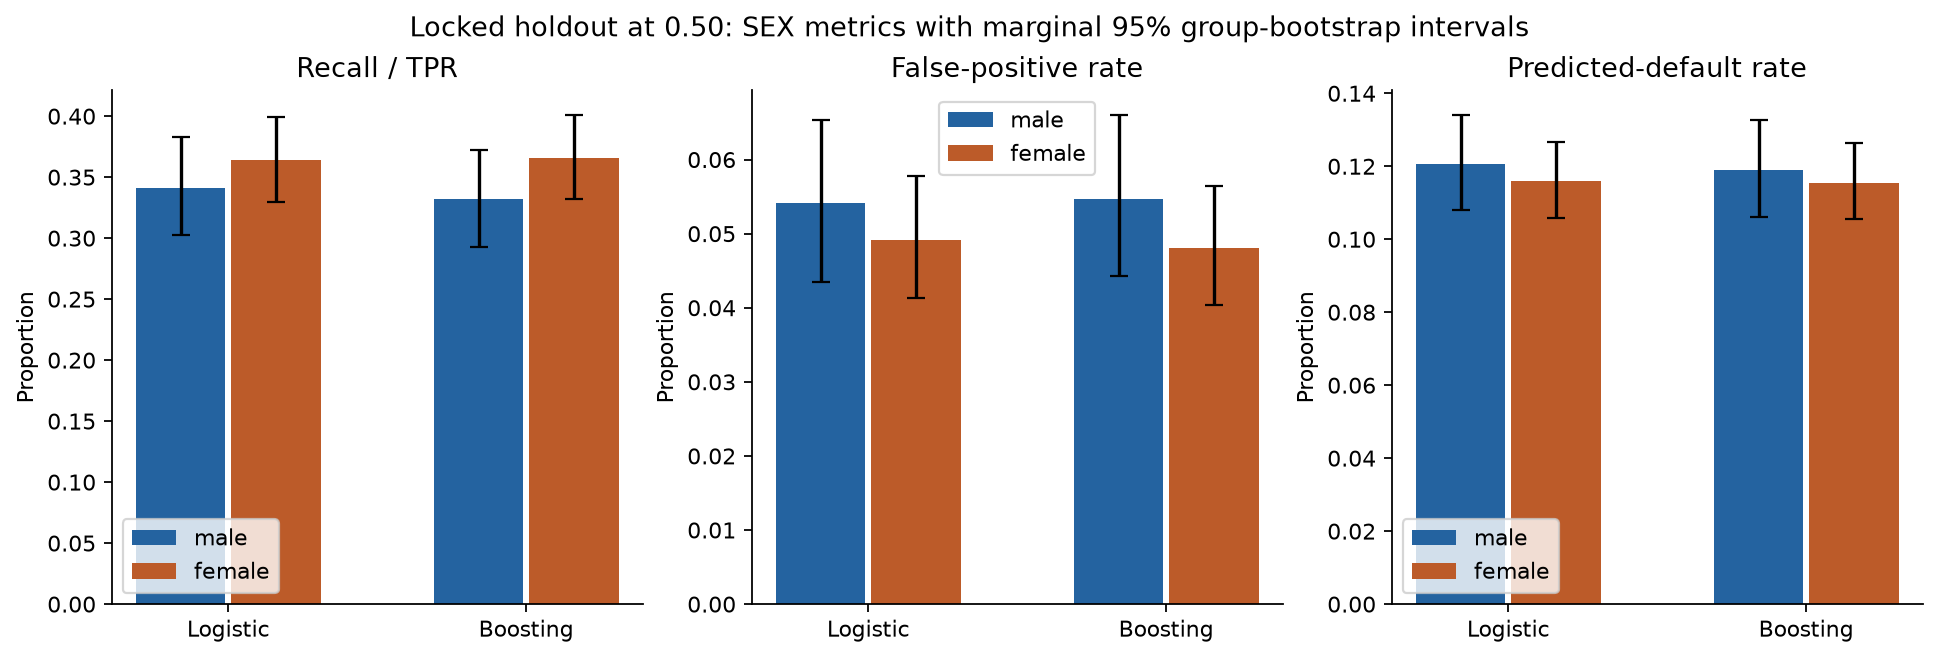

In [3]:
groups = read_table('group_metrics_threshold_050')
display(groups)
display(Image(filename=str(FIGURE_DIR / 'group_metrics_threshold_050.png')))


## Demographic parity, equal opportunity and equalized odds

Selection-rate difference is female minus male. Demographic-parity difference
uses max-minus-min (unsigned); its ratio is min/max. The separately labeled
selection-rate ratio is female/male. No normative group mapping or legal rule is used.
Equal opportunity here compares default-detection TPR. Equalized odds assesses
both TPR and FPR. A smaller numerical gap is closer sample parity for that measure,
not a declaration of overall fairness.
[Metric definitions](https://fairlearn.org/main/user_guide/assessment/common_fairness_metrics.html).

In [4]:
gaps = read_table('fairness_gaps_threshold_050')
display(gaps)
intervals = read_table('fairness_confidence_intervals')
key_metrics = ['selection_rate_difference', 'recall_difference', 'fpr_difference',
               'precision_difference', 'specificity_difference', 'safe_rga_difference']
display(intervals[intervals.metric.isin(key_metrics)])
display(intervals[(intervals.scope != 'female_vs_male') & intervals.metric.isin(['selection_rate','recall','fpr','precision','safe_rga'])])


,model,threshold,metric,value,convention,parity_reference
0,logistic,0.5,selection_rate_difference,-0.004541,female minus male,0
1,logistic,0.5,accuracy_difference,0.020540,female minus male,0
2,logistic,0.5,balanced_accuracy_difference,0.014123,female minus male,0
3,logistic,0.5,precision_difference,0.011494,female minus male,0
4,logistic,0.5,recall_difference,0.023238,female minus male,0
5,logistic,0.5,specificity_difference,0.005008,female minus male,0
6,logistic,0.5,fpr_difference,-0.005008,female minus male,0
7,logistic,0.5,fnr_difference,-0.023238,female minus male,0
8,logistic,0.5,npv_difference,0.020849,female minus male,0
9,logistic,0.5,f1_difference,0.022544,female minus male,0


,model,scope,metric,estimate,ci_lower,ci_upper,valid_repetitions,undefined_repetitions,confidence_level,method
40,logistic,female_vs_male,selection_rate_difference,-0.004541,-0.021461,0.012099,2000,0,0.95,whole-predictor-group percentile bootstrap; ma...
43,logistic,female_vs_male,precision_difference,0.011494,-0.061176,0.084606,2000,0,0.95,whole-predictor-group percentile bootstrap; ma...
44,logistic,female_vs_male,recall_difference,0.023238,-0.029016,0.077510,2000,0,0.95,whole-predictor-group percentile bootstrap; ma...
45,logistic,female_vs_male,specificity_difference,0.005008,-0.007852,0.018822,2000,0,0.95,whole-predictor-group percentile bootstrap; ma...
46,logistic,female_vs_male,fpr_difference,-0.005008,-0.018822,0.007852,2000,0,0.95,whole-predictor-group percentile bootstrap; ma...
65,gradient_boosting,female_vs_male,selection_rate_difference,-0.003434,-0.020292,0.013090,2000,0,0.95,whole-predictor-group percentile bootstrap; ma...
68,gradient_boosting,female_vs_male,precision_difference,0.025436,-0.045443,0.099854,2000,0,0.95,whole-predictor-group percentile bootstrap; ma...
69,gradient_boosting,female_vs_male,recall_difference,0.033525,-0.016804,0.086422,2000,0,0.95,whole-predictor-group percentile bootstrap; ma...
70,gradient_boosting,female_vs_male,specificity_difference,0.006610,-0.006197,0.019661,2000,0,0.95,whole-predictor-group percentile bootstrap; ma...
71,gradient_boosting,female_vs_male,fpr_difference,-0.006610,-0.019661,0.006197,2000,0,0.95,whole-predictor-group percentile bootstrap; ma...


,model,scope,metric,estimate,ci_lower,ci_upper,valid_repetitions,undefined_repetitions,confidence_level,method
0,logistic,male,selection_rate,0.120632,0.108061,0.134082,2000,0,0.95,whole-predictor-group percentile bootstrap; ma...
3,logistic,male,precision,0.655172,0.595743,0.711747,2000,0,0.95,whole-predictor-group percentile bootstrap; ma...
4,logistic,male,recall,0.341113,0.302703,0.382788,2000,0,0.95,whole-predictor-group percentile bootstrap; ma...
6,logistic,male,fpr,0.054142,0.043527,0.065313,2000,0,0.95,whole-predictor-group percentile bootstrap; ma...
10,logistic,female,selection_rate,0.116091,0.105950,0.126691,2000,0,0.95,whole-predictor-group percentile bootstrap; ma...
13,logistic,female,precision,0.666667,0.619643,0.710790,2000,0,0.95,whole-predictor-group percentile bootstrap; ma...
14,logistic,female,recall,0.364351,0.329632,0.399244,2000,0,0.95,whole-predictor-group percentile bootstrap; ma...
16,logistic,female,fpr,0.049134,0.041294,0.057735,2000,0,0.95,whole-predictor-group percentile bootstrap; ma...
20,gradient_boosting,male,selection_rate,0.118968,0.106224,0.132806,2000,0,0.95,whole-predictor-group percentile bootstrap; ma...
23,gradient_boosting,male,precision,0.646853,0.587167,0.703458,2000,0,0.95,whole-predictor-group percentile bootstrap; ma...


## Uncertainty

2,000 whole-predictor-group bootstrap replicates, seed 42. Sample complete exact
22-predictor groups with replacement, preserving groups that span SEX categories.
Both models use the same samples. Confusion metrics use row multiplicities; SAFE
RGA is called on explicitly expanded sampled records. Intervals use 2.5th/97.5th
percentiles, linear interpolation, with valid/undefined counts per metric.

The important signed TPR/FPR/selection/RGA intervals include zero. That does not
prove equivalence or rule out material gaps. CIs are marginal and unadjusted for
multiple metrics; no model-comparison or causal-discrimination test is performed.
Absolute-gap CIs are nonnegative by construction and cannot establish disparity
merely from a positive lower endpoint. Retraining/future-shift uncertainty is excluded.

In [5]:
replicates = read_table('bootstrap_replicates')
display(replicates.groupby(['model','scope']).sample_records.agg(['count','min','mean','max']))
display(intervals[['valid_repetitions','undefined_repetitions']].drop_duplicates())


count   min       mean   max
model             scope                                       
gradient_boosting female           2000  5982  5996.0285  6012
                  female_vs_male   2000  5982  5996.0285  6012
                  male             2000  5982  5996.0285  6012
logistic          female           2000  5982  5996.0285  6012
                  female_vs_male   2000  5982  5996.0285  6012
                  male             2000  5982  5996.0285  6012

,valid_repetitions,undefined_repetitions
0,2000,0


## Exploratory holdout threshold sensitivity

This stage authorizes a descriptive 0.10–0.70 grid in 0.05 increments, without
choosing any operating threshold. This is an extension of reporting only: the
holdout remains prohibited for optimization and model development. Class 1 means
probability > threshold, as in the fixed reference predictions. The table includes
overall recall/precision/flagged rate, both groups' TPR/FPR/selection rates and gaps.
No optimum is identified and 0.50 remains the reference.

,model,threshold,overall_recall,overall_precision,overall_selection_rate,male_recall,female_recall,recall_difference,male_fpr,female_fpr,fpr_difference,male_selection_rate,female_selection_rate,selection_rate_difference,selection_rate_ratio_female_to_male
0,logistic,0.10,0.951515,0.252920,0.828219,0.962298,0.943644,-0.018655,0.791554,0.794627,0.003073,0.831115,0.826281,-0.004834,0.994183
1,logistic,0.15,0.737879,0.346004,0.469480,0.754039,0.726081,-0.027958,0.390363,0.395900,0.005537,0.474626,0.466036,-0.008590,0.981902
2,logistic,0.20,0.590152,0.451594,0.287692,0.594255,0.587156,-0.007099,0.205739,0.200071,-0.005668,0.295757,0.282294,-0.013463,0.954479
3,logistic,0.25,0.533333,0.521095,0.225317,0.540395,0.528178,-0.012217,0.150514,0.130435,-0.020080,0.240849,0.214922,-0.025927,0.892353
4,logistic,0.30,0.479545,0.555263,0.190127,0.481149,0.478375,-0.002774,0.120195,0.100742,-0.019453,0.203827,0.180958,-0.022869,0.887801
5,logistic,0.35,0.435606,0.598335,0.160274,0.427289,0.441678,0.014389,0.090958,0.077059,-0.013899,0.168885,0.154510,-0.014375,0.914882
6,logistic,0.40,0.404545,0.637232,0.139760,0.396768,0.410223,0.013454,0.071467,0.060799,-0.010668,0.146839,0.135022,-0.011816,0.919528
7,logistic,0.45,0.384091,0.653351,0.129420,0.369838,0.394495,0.024657,0.062263,0.054436,-0.007827,0.133527,0.126670,-0.006857,0.948647
8,logistic,0.50,0.354545,0.661952,0.117912,0.341113,0.364351,0.023238,0.054142,0.049134,-0.005008,0.120632,0.116091,-0.004541,0.962357
9,logistic,0.55,0.333333,0.671756,0.109239,0.317774,0.344692,0.026918,0.049269,0.043832,-0.005437,0.111481,0.107739,-0.003741,0.966439


recall_difference           fpr_difference            \
                                min       max            min       max   
model                                                                    
gradient_boosting         -0.024353  0.046182      -0.030183 -0.004748   
logistic                  -0.027958  0.026918      -0.020080  0.005537   

                  selection_rate_difference            
                                        min       max  
model                                                  
gradient_boosting                 -0.034014  0.000969  
logistic                          -0.025927 -0.002683

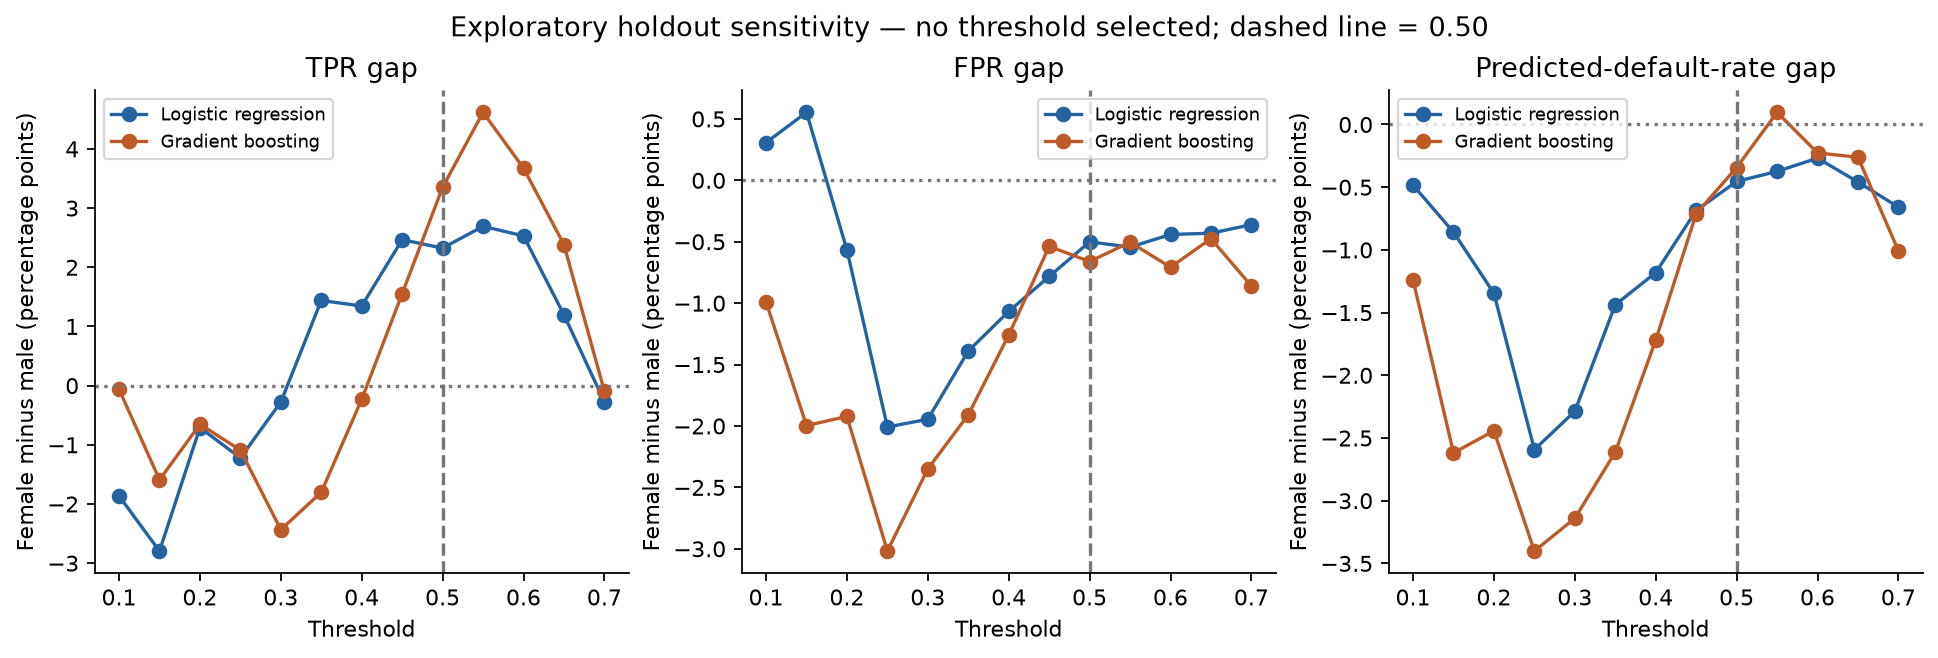

In [6]:
sensitivity = read_table('threshold_fairness_sensitivity')
columns = ['model','threshold','overall_recall','overall_precision','overall_selection_rate',
           'male_recall','female_recall','recall_difference','male_fpr','female_fpr','fpr_difference',
           'male_selection_rate','female_selection_rate','selection_rate_difference','selection_rate_ratio_female_to_male']
display(sensitivity[columns])
display(sensitivity.groupby('model')[['recall_difference','fpr_difference','selection_rate_difference']].agg(['min','max']))
display(Image(filename=str(FIGURE_DIR / 'fairness_gaps_vs_threshold.png')))


TPR-gap direction changes for both models across the grid. Logistic's FPR gap
also changes sign; boosting's remains negative. Boosting's selection gap crosses
zero, while logistic's remains negative. Apparent disparity depends on the chosen
threshold and metric. No simultaneous uncertainty bands were fitted for these curves.

## Actual SAFE package and pipeline adapter

The inspected upstream commit is `1e5f2a84d183c741fecaa682f2b9d496c142bd45`;
installed core matches exactly and fairness/utils differ only in whitespace.
The installed distribution version is 0.8.3; it has no recorded install commit.
The upstream example uses gender 0/1 for its own dataset. Our 1/2 coding stays intact.

SAFE receives aligned positional DataFrames containing the original predictors plus
SEX. Its function resets indices, enumerates groups from training SEX frequencies
and recomputes probabilities through sklearn's classifier detection. The read-only
adapter advertises classifier tags and selects only the saved pipeline's 22 feature
names before delegation; ID/SEX never enter that predictor matrix. Full and subgroup
predictions reproduce the saved scores. No fit method is allowed.

The actual package function returns a sentence containing max(group RGA) minus
min(group RGA). The raw sentence is retained. It does not assign privileged status.
The supplied yhat is checked, but subgroup scores are recomputed internally.
The wrapper does not modify or reproduce the package's metric formula.
[SAFE reference](https://github.com/GolnooshBabaei/safeaipackage).

,model,SEX,group,records,RGA,ROC-AUC,Average Precision (AP),implementation,package_version
0,logistic,NaN,overall,5996,0.756949,0.756949,0.527009,safeaipackage.core.rga,0.8.3
1,logistic,1.0,male,2404,0.761307,0.761307,0.528571,safeaipackage.core.rga,0.8.3
2,logistic,2.0,female,3592,0.753388,0.753388,0.528520,safeaipackage.core.rga,0.8.3
3,gradient_boosting,NaN,overall,5996,0.778132,0.778132,0.552136,safeaipackage.core.rga,0.8.3
4,gradient_boosting,1.0,male,2404,0.774070,0.774070,0.541386,safeaipackage.core.rga,0.8.3
5,gradient_boosting,2.0,female,3592,0.780525,0.780525,0.563114,safeaipackage.core.rga,0.8.3


,model,male_RGA,female_RGA,female_minus_male,package_parity,raw_package_return,implementation,package_version
0,logistic,0.761307,0.753388,-0.007919,0.007919,The RGA-based imparity between the protected g...,safeaipackage.check_fairness.compute_rga_parity,0.8.3
1,gradient_boosting,0.774070,0.780525,0.006455,0.006455,The RGA-based imparity between the protected g...,safeaipackage.check_fairness.compute_rga_parity,0.8.3


RGA and ROC-AUC numerically coincide on this binary audit: True


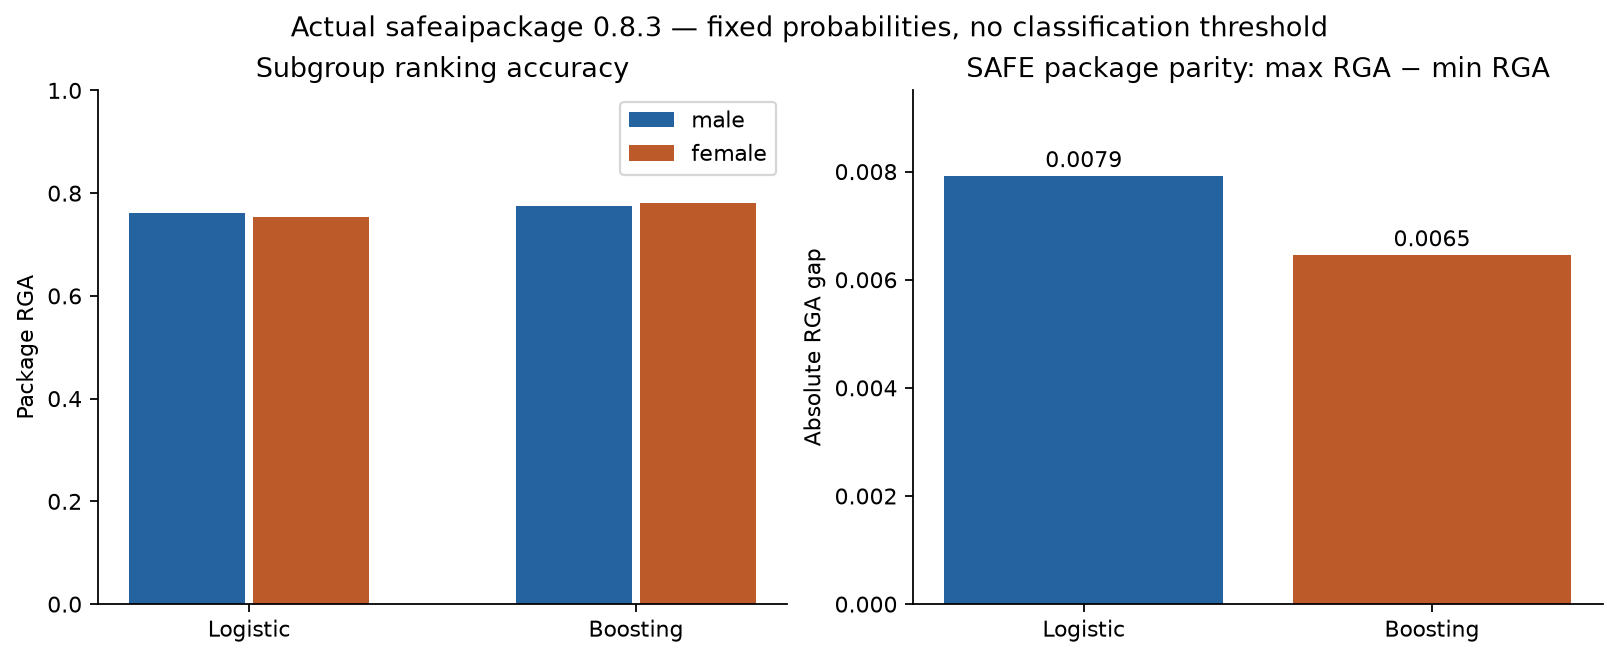

In [7]:
rga = read_table('safe_rga_results')
parity = read_table('safe_rga_parity')
display(rga)
display(parity)
print('RGA and ROC-AUC numerically coincide on this binary audit:', np.allclose(rga.RGA, rga['ROC-AUC'], atol=1e-12, rtol=0))
display(Image(filename=str(FIGURE_DIR / 'safe_rga_parity.png')))


RGA evaluates normalized ranking agreement and the SAFE framework extends to
nonbinary outcomes. Its values happen to coincide with ROC-AUC here; that is reported
as a result of the actual binary-outcome implementation, not assumed interchangeability
in general. SAFE parity compares within-group ranking accuracy without a classification
threshold; it does not measure the fraction flagged or errors at one boundary.

In [8]:
display(read_table('conventional_vs_safe_comparison'))


,model,selection_rate_difference,selection_rate_ratio_female_to_male,recall_difference,fpr_difference,equalized_odds_max_absolute_gap,safe_RGA_female_minus_male,SAFE_absolute_parity_gap
0,gradient_boosting,-0.003434,0.971136,0.033525,-0.006610,0.033525,0.006455,0.006455
1,logistic,-0.004541,0.962357,0.023238,-0.005008,0.023238,-0.007919,0.007919


## Comparison of fairness frameworks

Boosting has a smaller absolute SAFE RGA parity gap (about 0.00645 versus 0.00792),
but larger TPR/FPR absolute gaps at 0.50. Its selection-rate gap is smaller.
Logistic has lower female ranking accuracy but higher female TPR at 0.50; for
boosting, both female RGA and TPR are higher. These are descriptive point estimates
with uncertain signed gaps, not a ranking of overall fairness. The disagreement
reflects different questions rather than a reason to force the frameworks to agree.

## Descriptive associations and unawareness limitation

SEX exclusion is not proof of fairness. Training-only associations describe numeric
standardized mean differences and categorical Cramer's V, with no causal/proxy model,
feature removal or retraining. SMD uses female minus male means divided by the square
root of their average sample variances. Cramer's V uses uncorrected chi-square.
Ranks are kept separate for different measures; no p-value screening or significance
cutoff is used. Financial skew is shown through medians and quartiles.

In [9]:
associations = read_table('proxy_descriptive_associations')
display(associations[associations.feature_type == 'numeric'].sort_values('association', ascending=False))
display(associations[associations.feature_type == 'categorical'].sort_values('association', ascending=False))
display(read_table('proxy_category_distributions'))


,feature,feature_type,partition,association_measure,association,signed_standardized_mean_difference_female_minus_male,male_mean,female_mean,male_median,female_median,male_q25,female_q25,male_q75,female_q75
1,AGE,numeric,training,absolute standardized mean difference,0.190207,-0.190207,36.487242,34.738154,35.0,33.0,29.00,28.00,43.00,40.00
2,BILL_AMT1,numeric,training,absolute standardized mean difference,0.069175,-0.069175,54193.955820,49065.834022,24127.0,21174.5,4790.25,3002.75,68821.50,65627.75
3,BILL_AMT2,numeric,training,absolute standardized mean difference,0.064462,-0.064462,51788.397722,47185.612328,22694.0,20382.0,4144.75,2500.00,65958.00,62445.75
4,BILL_AMT3,numeric,training,absolute standardized mean difference,0.053021,-0.053021,49062.901307,45411.459986,20542.5,19565.0,3411.50,2318.75,61118.75,59501.50
0,LIMIT_BAL,numeric,training,absolute standardized mean difference,0.051911,0.051911,163249.261915,170025.895317,130000.0,150000.0,50000.00,70000.00,240000.00,240000.00
5,BILL_AMT4,numeric,training,absolute standardized mean difference,0.045997,-0.045997,44944.803880,41976.941322,19297.5,18656.5,2879.00,2000.00,55371.75,53592.50
7,BILL_AMT6,numeric,training,absolute standardized mean difference,0.038081,-0.038081,40047.266660,37769.770868,17631.0,16330.5,1362.00,1149.50,49116.75,48867.25
6,BILL_AMT5,numeric,training,absolute standardized mean difference,0.036145,-0.036145,41492.417334,39286.064050,18381.5,17787.5,2081.25,1590.25,50333.25,49968.75
9,PAY_AMT2,numeric,training,absolute standardized mean difference,0.013275,-0.013275,6040.256537,5773.790496,2000.0,2047.5,832.00,852.00,5000.00,5000.00
10,PAY_AMT3,numeric,training,absolute standardized mean difference,0.010392,-0.010392,5324.844264,5143.228099,1682.0,1957.5,390.00,397.75,4500.00,4600.00


,feature,feature_type,partition,association_measure,association,signed_standardized_mean_difference_female_minus_male,male_mean,female_mean,male_median,female_median,male_q25,female_q25,male_q75,female_q75
17,PAY_2,categorical,training,Cramer's V (uncorrected),0.079429,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
18,PAY_3,categorical,training,Cramer's V (uncorrected),0.075903,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
16,PAY_0,categorical,training,Cramer's V (uncorrected),0.071219,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
19,PAY_4,categorical,training,Cramer's V (uncorrected),0.070416,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
20,PAY_5,categorical,training,Cramer's V (uncorrected),0.062674,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
21,PAY_6,categorical,training,Cramer's V (uncorrected),0.051194,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
15,MARRIAGE,categorical,training,Cramer's V (uncorrected),0.026589,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
14,EDUCATION,categorical,training,Cramer's V (uncorrected),0.025462,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,feature,category,SEX,group,records,within_group_fraction
0,EDUCATION,1,1,male,3453,0.364087
1,EDUCATION,2,1,male,4306,0.454028
2,EDUCATION,3,1,male,1580,0.166596
3,EDUCATION,4,1,male,145,0.015289
4,EDUCATION,1,2,female,5007,0.344835
...,...,...,...,...,...,...
137,PAY_6,4,2,female,18,0.001240
138,PAY_6,5,2,female,3,0.000207
139,PAY_6,6,2,female,6,0.000413
140,PAY_6,7,2,female,17,0.001171


AGE shows the largest numeric mean difference (absolute SMD around 0.19).
Repayment-status categories show the largest categorical associations (Cramer's V
around 0.07–0.08). These descriptions do not establish prohibited proxy use or causal
discrimination. A dedicated causal/proxy methodology would need separate design.

## Readiness, limitations and decisions

Potential later intersectional groups include SEX × age bands, education and marriage.
Before any fairness claims, check total/default/non-default and independent-group
counts per cell, define small-cell handling, and plan multiple-comparison treatment.
No formal intersectional experiment was conducted.

The historical holdout's earlier inspection remains disclosed. Results condition
on fixed models, observed groups and a historical Taiwanese sample. There is no
agreed materiality tolerance, operational approval policy or causal identification.
Choose the relevant harms, fairness concepts and practical tolerances before
deciding follow-up. Any later threshold choice needs training-only development;
this holdout sweep cannot select it. Decide whether a focused proxy/intersectional
follow-up or Explainability should come next. Both models and 0.50 remain in place.
Mitigation, SHAP/RGE, RGR, PSI and governance work have not begun.

[Full fairness report and file inventory](../outputs/fairness_evaluation_report.md).